In [1]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt
import time

# Taller: Integración y diferenciación numérica
# Ejercicio 1 - Python con SciPy
# Integrantes:
# Jimmy Alexander Calderon Trujillo
# Sebastian Barahona

# Límites de integración
a = 0.0
b = 8.0

# Valor de referencia obtenido analíticamente
I_ref = 2.559824508302

print("TALLER DE INTEGRACIÓN Y DIFERENCIACIÓN NUMÉRICA")
print("Ejercicio 1 - Python con SciPy")
print()
print(f"Valor de referencia de la integral: {I_ref:.12f}")

TALLER DE INTEGRACIÓN Y DIFERENCIACIÓN NUMÉRICA
Ejercicio 1 - Python con SciPy

Valor de referencia de la integral: 2.559824508302


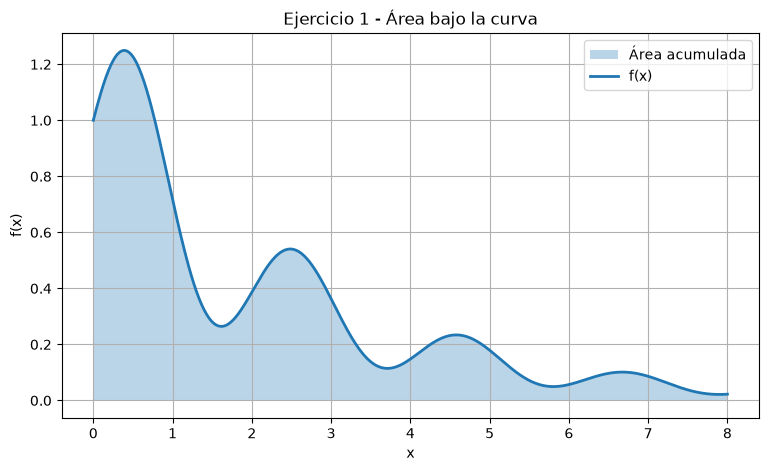

In [2]:
# Definición de la función del ejercicio
def f(x):
    return np.exp(-0.4 * x) * (1 + 0.5 * np.sin(3 * x))

# Puntos para visualizar la función
x = np.linspace(a, b, 500)
y = f(x)

# Gráfica
plt.figure(figsize=(9, 5))
plt.fill_between(x, y, alpha=0.3, label="Área acumulada")
plt.plot(x, y, linewidth=2, label="f(x)")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Ejercicio 1 - Área bajo la curva")
plt.grid(True)
plt.legend()
plt.show()

In [3]:
# ============================================================
# INTEGRACIÓN ADAPTATIVA CON scipy.integrate.quad
# ============================================================

# Tolerancias
epsabs = 1e-10
epsrel = 1e-10

# Medición del tiempo
inicio = time.perf_counter()

resultado_quad, error_estimado_quad = quad(
    f,
    a,
    b,
    epsabs=epsabs,
    epsrel=epsrel
)

fin = time.perf_counter()

tiempo_quad = fin - inicio

# Error real respecto al valor de referencia
error_real_quad = abs(I_ref - resultado_quad)

# Resultados
print("INTEGRACIÓN ADAPTATIVA CON SCIPY")
print("---------------------------------------------")
print(f"Resultado SciPy      : {resultado_quad:.12f}")
print(f"Error estimado SciPy : {error_estimado_quad:.6e}")
print(f"Error vs referencia  : {error_real_quad:.6e}")
print(f"Tolerancia absoluta  : {epsabs:.6e}")
print(f"Tolerancia relativa  : {epsrel:.6e}")
print(f"Tiempo SciPy (s)     : {tiempo_quad:.6e}")

INTEGRACIÓN ADAPTATIVA CON SCIPY
---------------------------------------------
Resultado SciPy      : 2.559824508302
Error estimado SciPy : 1.458303e-10
Error vs referencia  : 6.350476e-14
Tolerancia absoluta  : 1.000000e-10
Tolerancia relativa  : 1.000000e-10
Tiempo SciPy (s)     : 1.904742e-03


In [4]:
# ============================================================
# REGLA COMPUESTA DEL TRAPECIO
# ============================================================

valores_n = [10, 20, 50, 100, 500, 1000]

print("REGLA COMPUESTA DEL TRAPECIO")
print("--------------------------------------------------------------------------")
print("   n          Integral             Error absoluto       Tiempo (s)")
print("--------------------------------------------------------------------------")

for n in valores_n:

    inicio = time.perf_counter()

    # Tamaño del paso
    h = (b - a) / n

    # Puntos de la partición
    x_trap = np.linspace(a, b, n + 1)

    # Evaluación de la función
    y_trap = f(x_trap)

    # Regla compuesta del trapecio
    I_trap = h * (
        0.5 * y_trap[0]
        + np.sum(y_trap[1:-1])
        + 0.5 * y_trap[-1]
    )

    fin = time.perf_counter()

    tiempo = fin - inicio

    # Error respecto al valor de referencia
    error_abs = abs(I_ref - I_trap)

    print(
        f"{n:4d}     "
        f"{I_trap:16.12f}     "
        f"{error_abs:14.6e}     "
        f"{tiempo:12.6e}"
    )

REGLA COMPUESTA DEL TRAPECIO
--------------------------------------------------------------------------
   n          Integral             Error absoluto       Tiempo (s)
--------------------------------------------------------------------------
  10       2.494072510186       6.575200e-02     1.164809e-03
  20       2.544929716212       1.489479e-02     4.268000e-04
  50       2.557502776878       2.321731e-03     5.527500e-04
 100       2.559246207984       5.783003e-04     2.789410e-04
 500       2.559801403459       2.310484e-05     1.805375e-03
1000       2.559818732303       5.775999e-06     9.192330e-04
